In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [10]:
path = '/home/kale-chen/Documents/PET/MiniPET/OldData/run118.dat'
#path = '/home/kale-chen/Documents/PET/MiniPET/TPPTmoduletesting/goodT0.dat'
#path = '/home/kale-chen/Documents/PET/MDA_04112026/Data/Run1_FullPhantom_PMMA_with_Film_121_2MeV_10MU_10min_HWTrigOn_coinc.dat'
#path = '/home/kale-chen/Documents/PET/MiniPET/CTR_new_modules2/withcrystals/10min.dat'
#path = '/home/kale-chen/Documents/PET/MiniPET/CTR_new_modules2/withcrystals/ovt1scan_coinc.dat'
df = pd.read_csv(path, sep = '\t', header = None)
print(len(df))
df.head()

2735488


,0,1,2,3,4,5,6,7,8,9
0,1,0,6471509220361,1.773857,262741,12,0,6471509218573,21.533596,262453
1,10,0,6472209941772,11.240562,262657,16,0,6472209941642,18.493317,262495
2,12,0,6472557184831,26.147591,262722,11,0,6472557187332,22.960865,262451
3,5,0,6475378202713,11.468636,262683,4,0,6475378202840,10.422565,262414
4,11,0,6475874411808,19.499065,262707,7,0,6475874410967,15.901871,262469


In [11]:
t0, tf = np.min(df.iloc[:, 2]), np.max(df.iloc[:, 2])
print(t0, tf, (tf - t0) / 1e12)

6471509220361 1806470919314302 1799.999410093941


In [3]:
idls = np.array(df.iloc[:, 4])
idrs = np.array(df.iloc[:, 9])
print(len(np.unique(idls)))
print(len(np.unique(idrs)))

128
128


In [4]:
eventcounts = np.zeros((len(np.unique(idls)), len(np.unique(idrs))))
for i in tqdm(range(0, len(idls), 1000000)):
    chunkl = idls[i:i+1000000]
    chunkr = idrs[i:i+1000000]
    eidls = chunkl % len(np.unique(idls))
    eidrs = chunkr % len(np.unique(idrs))
    np.add.at(eventcounts, (eidls, eidrs), 1)
print(eventcounts)

  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 16.51it/s]

[[  19.   14.   28. ...  287.   31. 1779.]
 [   9.   10.   21. ...  750.   45.  685.]
 [  19.   16.  384. ... 2024. 2049.   92.]
 ...
 [  67.  202. 2388. ...   27.  158.   13.]
 [  25.   22.  688. ...  117. 2861.   33.]
 [1682. 2138.  131. ...   27.   48.   26.]]


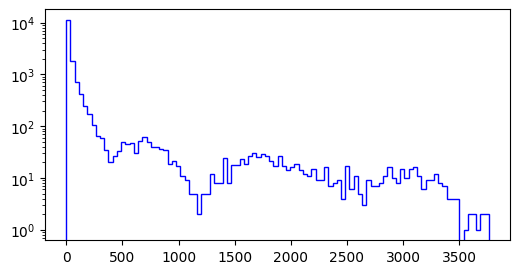

In [5]:
plt.figure(figsize = (6, 3))
plt.hist(eventcounts.flatten(), bins = 100, color = 'blue', histtype = 'step')
plt.yscale('log')
plt.show()

In [6]:
pairs = []
thresh = 3000
for i in range(len(eventcounts)):
    for j in range(len(eventcounts[i])):
        if eventcounts[i][j] > thresh:
            pairs.append((i, j))
print(len(pairs))


131


110 19 3393
7.43, 26.62
12.43, 23.58


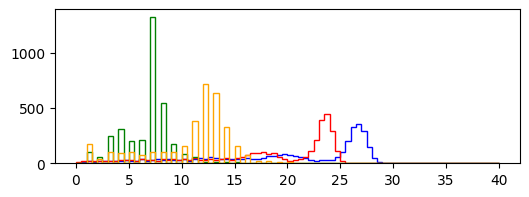

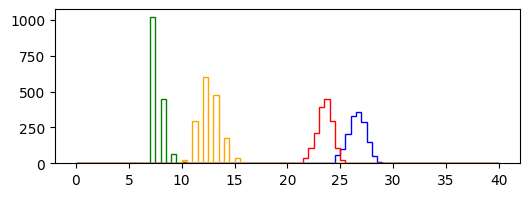

In [9]:
pairindex = np.random.randint(0, len(pairs))
#pairindex = 3
idl, idr = pairs[pairindex]
lordata = df[(df.iloc[:, 4] % len(np.unique(idls)) == idl) & (df.iloc[:, 9] % len(np.unique(idrs)) == idr)]
print(idl, idr, len(lordata))
plt.figure(figsize=(6, 2))
bins = np.linspace(0, 40, 81)
bincenters = (bins[:-1] + bins[1:]) / 2
#mask = (lordata.iloc[:, 3] > 20) & (lordata.iloc[:, 8] > 20)
mask = np.ones(len(lordata), dtype = bool)
hist1 = plt.hist(lordata.iloc[:, 3][mask], bins = bins, color = 'blue', histtype = 'step')[0]
hist2 = plt.hist(lordata.iloc[:, 8][mask], bins = bins, color = 'red', histtype = 'step')[0]
hist3 = plt.hist(lordata.iloc[:, 0][mask], bins = bins, color = 'green', histtype = 'step')[0]
hist4 = plt.hist(lordata.iloc[:, 5][mask], bins = bins, color = 'orange', histtype = 'step')[0]
def gaussian(x, a, mu, sig):
    return a * np.exp(-(x - mu)**2 / (2 * sig**2))
plt.figure(figsize = (6, 2))
popt, _ = curve_fit(gaussian, bincenters, hist1, 
        p0 = [np.max(hist1), bincenters[np.argmax(hist1)], 1],
        bounds = ((0, bincenters[np.argmax(hist1)] - 5, 0), (np.inf, bincenters[np.argmax(hist1)] + 5, np.inf)))
mask = lordata.iloc[:, 3] > popt[1] - 2.5 * popt[2]
plt.hist(lordata.iloc[:, 3][mask], bins = bins, color = 'blue', histtype = 'step')
plt.hist(lordata.iloc[:, 0][mask], bins = bins, color = 'green', histtype = 'step')
print(f'{np.mean(lordata.iloc[:, 0][mask]):.2f}, {popt[1]:.2f}')
popt, _ = curve_fit(gaussian, bincenters, hist2, 
        p0 = [np.max(hist2), bincenters[np.argmax(hist2)], 1],
        bounds = ((0, bincenters[np.argmax(hist2)] - 5, 0), (np.inf, bincenters[np.argmax(hist2)] + 5, np.inf)))
mask = lordata.iloc[:, 8] > popt[1] - 2.5 * popt[2]
plt.hist(lordata.iloc[:, 8][mask], bins = bins, color = 'red', histtype = 'step')
plt.hist(lordata.iloc[:, 5][mask], bins = bins, color = 'orange', histtype = 'step')
print(f'{np.mean(lordata.iloc[:, 5][mask]):.2f}, {popt[1]:.2f}')
plt.show()

plt.show()

In [16]:
eventcounts = np.zeros(3072)
idls = np.array(df.iloc[:, 4])
for i in tqdm(range(0, len(idls), 1000000)):
    chunkl = idls[i:i+1000000]
    eidls = chunkl % 3072
    np.add.at(eventcounts, eidls, 1)
print(eventcounts)

  0%|          | 0/13 [00:00<?, ?it/s]

100%|██████████| 13/13 [00:00<00:00, 34.85it/s]

[0. 0. 0. ... 0. 0. 0.]


100%|██████████| 13/13 [00:00<00:00, 50.29it/s]


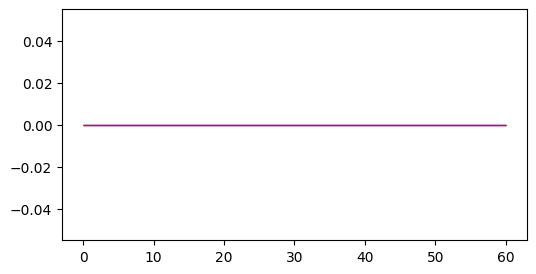

In [17]:
idl = 0
energies = []
mhn = []
for i in tqdm(range(0, len(idls), 1000000)):
    chunk = df.iloc[i:i+1000000]
    chunk = chunk.to_numpy()
    chunk = chunk[chunk[:, 4] % 3072 == idl]
    energies.extend(chunk[:, 3])
    mhn.extend(chunk[:, 0])
energies = np.array(energies)
mhn = np.array(mhn)
mask = (energies > 25)
#mask = np.ones(len(energies), dtype = bool)
plt.figure(figsize = (6, 3))
plt.hist(energies[mask], bins = np.linspace(0, 60, 121), color = 'blue', histtype = 'step')
plt.hist(mhn[mask], bins = np.linspace(0, 60, 121), color = 'red', histtype = 'step')
plt.show()


In [1]:
timediffs = df.iloc[:, 2] - df.iloc[:, 7]
plt.figure(figsize = (6, 3))
plt.hist(timediffs, bins = np.linspace(-10000, 10000, 401))
plt.grid()
plt.show()



NameError: name 'df' is not defined